Computational biologists rarely work at the bench, but every dataset you'll analyse was produced by a lab technique with its own quirks, biases and failure modes. Knowing how the data was made tells you what can go wrong with it: why sequencing depth matters, why qPCR results are logarithmic, why a "batch effect" can look like biology. This chapter is a guided tour of the core techniques, with a small calculation for each.

:::eli5
Biologists have a toolbox. A **photocopier** for DNA (PCR) makes billions of copies of one small piece so there is enough to study. A **sieve** (a gel) sorts DNA pieces by size. A **reader** (a sequencer) turns DNA into text files of A, C, G and T. **Molecular scissors** (restriction enzymes and CRISPR) cut DNA at chosen places. Other tools count proteins, photograph cells, or test drugs on cells grown in dishes. Every number in the later chapters came out of one of these tools.
:::

## PCR: copying one piece of DNA a billion times

The **polymerase chain reaction** (Kary Mullis, 1983) copies a chosen stretch of DNA. You need two short **primers** (chapter P3), one matching each end of the target, a heat-stable DNA polymerase (originally from a hot-spring bacterium), and the four nucleotides. Then you cycle the temperature:

1. **Denature** at about 95 °C: the double helix separates into single strands.
2. **Anneal** at about 55–65 °C: primers stick to their matching sites (the temperature is set by the primers' melting temperature, chapter P3).
3. **Extend** at 72 °C: the polymerase copies from each primer.

Each cycle roughly doubles the target: 30 cycles give about 2³⁰ ≈ 10⁹ copies. In **quantitative PCR** (qPCR), a fluorescent dye reports the amount of DNA after every cycle. The cycle at which the signal crosses a threshold, the **Ct** (cycle threshold), tells you how much target the sample started with: each halving of the starting amount delays Ct by one cycle (at perfect efficiency).

:::math
With efficiency $E$ (1 = perfect doubling), after $c$ cycles $N_c = N_0 (1 + E)^c$. Setting $N_{Ct}$ equal to a fixed threshold $T$:

$$\text{Ct} = \frac{\log T - \log N_0}{\log(1 + E)},$$

a straight line in $\log_{10} N_0$ with slope $-1/\log_{10}(1+E)$: $-3.32$ cycles per 10-fold at $E = 1$. Fitting that line to a dilution series of known standards measures $E$ and converts any Ct into a starting amount.
:::

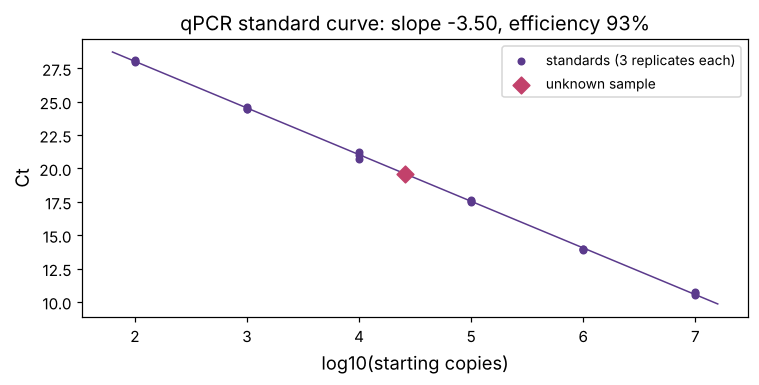

slope -3.495 -> efficiency 93.2% (true 93%); unknown sample: about 25,746 copies (true 25,000)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}
rng = np.random.default_rng(11)

true_E, threshold = 0.93, 1e10
def measure_ct(n0, reps=3):
    ct = (np.log10(threshold) - np.log10(n0)) / np.log10(1 + true_E)
    return ct + rng.normal(0, 0.15, reps)                 # pipetting and instrument noise

standards = 10.0 ** np.arange(7, 1, -1)                   # 10^7 ... 10^2 copies
cts = np.array([measure_ct(n) for n in standards])
x = np.repeat(np.log10(standards), 3); y = cts.ravel()
slope, intercept = np.polyfit(x, y, 1)
E_fit = 10 ** (-1 / slope) - 1

unknown_ct = measure_ct(2.5e4).mean()
unknown = 10 ** ((unknown_ct - intercept) / slope)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(x, y, color="#5b3a8c", s=18, label="standards (3 replicates each)")
xx = np.linspace(1.8, 7.2, 10); ax.plot(xx, slope * xx + intercept, color="#5b3a8c", lw=1)
ax.scatter(np.log10(unknown), unknown_ct, color="#c2416b", s=60, marker="D", zorder=3, label="unknown sample")
ax.set_xlabel("log10(starting copies)"); ax.set_ylabel("Ct"); ax.legend(fontsize=9)
ax.set_title(f"qPCR standard curve: slope {slope:.2f}, efficiency {E_fit:.0%}")
save_fig("qpcr"); plt.show()
R["slope"] = f"{slope:.2f}"; R["eff"] = f"{E_fit:.0%}"; R["unknown"] = f"{unknown:,.0f}"
print(f"slope {slope:.3f} -> efficiency {E_fit:.1%} (true {true_E:.0%}); unknown sample: about {unknown:,.0f} copies (true 25,000)")

![Figure P11-1. A simulated qPCR standard curve. Ct falls linearly with the logarithm of the starting amount. The fitted slope gives the efficiency, and the line converts the unknown sample's Ct into a copy number.](images/qpcr.png)

The fit gives a slope of -3.50 cycles per 10-fold, an efficiency of 93%, and estimates the unknown at about 25,746 copies (the true value was 25,000). The logarithmic scale has a practical consequence: a difference of one Ct is a two-fold difference in amount, so qPCR data are analysed as Ct differences, not raw Ct values.

:::lab
**Relative expression (ΔΔCt).** To compare a gene between a treated and an untreated sample, subtract each sample's Ct for a stable "housekeeping" gene (ΔCt), then subtract the control's ΔCt from the treated one's (ΔΔCt). The fold change is $2^{-\Delta\Delta \text{Ct}}$. A ΔΔCt of −3 means about 8-fold up. **RT-qPCR** first turns RNA into cDNA with reverse transcriptase (chapter P4); that is the COVID-19 PCR test.
:::

## Gel electrophoresis: sorting DNA by size

DNA's phosphate backbone is negatively charged, so in an electric field it moves towards the positive electrode. Run it through a gel of **agarose** (a seaweed polymer forming a mesh) and small pieces slip through faster than large ones. Stain the DNA and you see **bands**, one per fragment size. Over a useful range, distance travelled falls linearly with the *logarithm* of size, so a **ladder** of known sizes lets you estimate unknown fragment lengths.

In [2]:
ladder = np.array([20000, 10000, 7000, 5000, 4000, 3000, 2000, 1500, 1000, 700, 500])
def run_gel(bp, k=3.1, a=1.0):                       # migration distance in cm, plus a little noise
    return k * (5 - np.log10(bp)) * a + rng.normal(0, 0.04, np.size(bp))

d_ladder = run_gel(ladder)
fit = np.polyfit(d_ladder, np.log10(ladder), 1)
true_ecori = np.array([21226, 7421, 5804, 5643, 4878, 3530])    # lambda EcoRI fragments, from chapter P3
d_bands = run_gel(true_ecori)
est = 10 ** np.polyval(fit, d_bands)
for t, e in zip(true_ecori, est):
    print(f"true {t:6d} bp   estimated from the gel {e:7.0f} bp   error {100 * (e - t) / t:+5.1f}%")
R["max_err"] = f"{np.max(np.abs(est - true_ecori) / true_ecori):.0%}"

true  21226 bp   estimated from the gel   20895 bp   error  -1.6%
true   7421 bp   estimated from the gel    7137 bp   error  -3.8%
true   5804 bp   estimated from the gel    5540 bp   error  -4.5%
true   5643 bp   estimated from the gel    5551 bp   error  -1.6%
true   4878 bp   estimated from the gel    4687 bp   error  -3.9%
true   3530 bp   estimated from the gel    3353 bp   error  -5.0%


The size estimates are within about 5% of the true lambda fragment sizes, which is typical: gels give approximate sizes, and fragments within roughly 5% of each other (here the 5,804 and 5,643 bp pieces) run as one band unless the gel is optimised. Try the second tab of the playground, which uses the same real lambda fragment sizes.

::playground animations/lab_bench.html 640

## Cloning: putting a gene into a cell

To study or produce a protein, biologists **clone** its gene into a **plasmid**: a small circular DNA molecule that bacteria copy alongside their own genome. The classic recipe cuts the gene and the plasmid with the same restriction enzyme (chapter P3) so their sticky ends match, joins them with DNA ligase, puts the plasmid into bacteria, and selects the bacteria that took it up with an antibiotic-resistance gene carried on the plasmid. Modern methods (Gibson assembly, Golden Gate) join pieces by overlapping sequences instead. For human cells, genes are delivered with plasmids or engineered, disabled viruses (lentivirus, AAV), the same vehicles used in gene therapy.

## Sequencing: reading DNA as text

| Technology | Read length | Error rate | Typical use |
|---|---|---|---|
| **Sanger** (1977) | ~800 bases | very low | checking a single clone or mutation |
| **Illumina** (short reads) | 50–300 bases | ~0.1–1% | genomes, RNA-seq, almost everything in Part 2 |
| **PacBio HiFi** (long reads) | 10,000–25,000 | ~0.1% | assembling new genomes, structural variants |
| **Oxford Nanopore** (long reads) | up to >1,000,000 | a few % (improving) | long structures, direct RNA, portable field sequencing |

**Illumina sequencing by synthesis**, the workhorse: DNA is broken into fragments, adapters are attached, and each fragment is copied into a tiny cluster on a glass flow cell. Then, cycle by cycle, fluorescent nucleotides are added one base at a time, a camera records the colour of every cluster, and the dye is removed. Billions of clusters are read in parallel. Each base comes with a **quality score**.

:::math
The **Phred quality score** of a base call is $Q = -10 \log_{10} p$, where $p$ is the estimated probability that the call is wrong. Q10 means a 1 in 10 chance of error, Q20 1 in 100, Q30 1 in 1,000, Q40 1 in 10,000. FASTQ files store one quality character per base (chapter 1 shows how to decode them).
:::

In [3]:
Q = np.array([10, 20, 30, 40])
print("Q   error probability   errors per 150-base read")
for q in Q:
    p = 10 ** (-q / 10)
    print(f"{q:2d}  {p:17.4f}   {150 * p:8.2f}")
# a typical Illumina read: quality starts high and decays towards the end
pos = np.arange(150)
qual = np.clip(38 - 0.0009 * pos ** 2 + rng.normal(0, 1.5, 150), 2, 41)
exp_err = np.sum(10 ** (-qual / 10))
R["exp_err"] = f"{exp_err:.2f}"
print(f"expected errors in one simulated 150-base read: {exp_err:.2f}")

Q   error probability   errors per 150-base read
10             0.1000      15.00
20             0.0100       1.50
30             0.0010       0.15
40             0.0001       0.02
expected errors in one simulated 150-base read: 0.32


Even a good read is expected to contain a fraction of an error (0.32 for this simulated read), and errors concentrate towards its end, which is why pipelines trim low-quality tails. A single read therefore cannot prove a mutation; you need many independent reads covering the same position.

### Coverage: how many reads is enough?

If reads land at random, how evenly do they cover a genome? Eric Lander and Michael Waterman worked this out in 1988: with mean **coverage** $c$ (total bases read divided by genome length), the depth at a given position is approximately Poisson-distributed, and the fraction of the genome with no reads at all is about $e^{-c}$. Let's test it by "sequencing" phage lambda with simulated random reads:

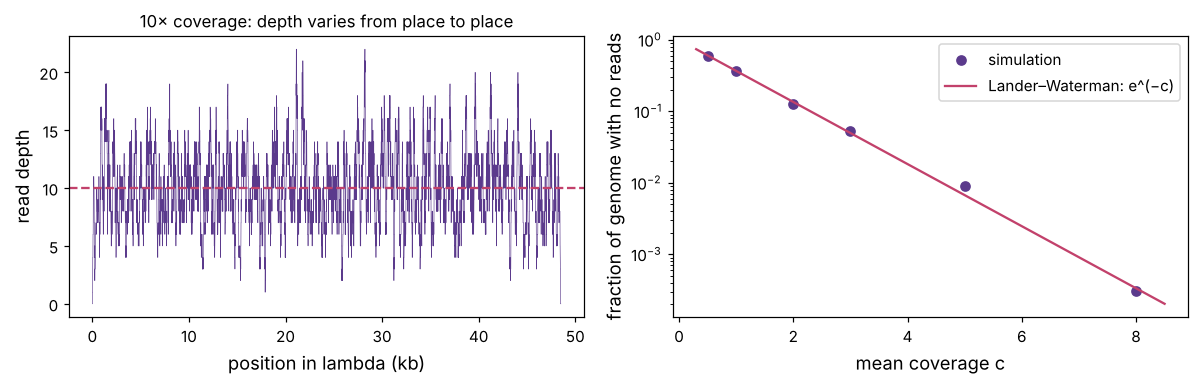

at 10x, fraction of positions with fewer than 5 reads: 2.7% (Poisson predicts 2.9%)


In [4]:
from Bio import SeqIO
lam_len = len(SeqIO.read("../03-dna/datasets/NC_001416.fasta", "fasta").seq)
read_len = 150

def simulate_depth(coverage):
    n_reads = int(coverage * lam_len / read_len)
    starts = rng.integers(0, lam_len - read_len, n_reads)
    diff = np.zeros(lam_len + 1)
    np.add.at(diff, starts, 1); np.add.at(diff, starts + read_len, -1)
    return np.cumsum(diff)[:lam_len]

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
depth = simulate_depth(10)
axs[0].plot(np.arange(lam_len) / 1000, depth, color="#5b3a8c", lw=0.4)
axs[0].axhline(10, color="#c2416b", ls="--"); axs[0].set_xlabel("position in lambda (kb)"); axs[0].set_ylabel("read depth")
axs[0].set_title("10× coverage: depth varies from place to place", fontsize=11)
cs = np.array([0.5, 1, 2, 3, 5, 8])
missing = [np.mean(simulate_depth(c) == 0) for c in cs]
axs[1].semilogy(cs, missing, "o", color="#5b3a8c", label="simulation")
cc = np.linspace(0.3, 8.5, 100); axs[1].semilogy(cc, np.exp(-cc), color="#c2416b", label="Lander–Waterman: e^(−c)")
axs[1].set_xlabel("mean coverage c"); axs[1].set_ylabel("fraction of genome with no reads"); axs[1].legend()
save_fig("coverage"); plt.show()
from scipy.stats import poisson
R["low10"] = f"{np.mean(depth < 5):.1%}"; R["pois_low10"] = f"{poisson.cdf(4, 10):.1%}"
print(f"at 10x, fraction of positions with fewer than 5 reads: {np.mean(depth < 5):.1%} (Poisson predicts {poisson.cdf(4, 10):.1%})")

![Figure P11-2. Left: read depth along phage lambda at 10× mean coverage, from simulated random 150-base reads. Right: the fraction of the genome left uncovered falls as e^(−c), exactly as Lander and Waterman predicted.](images/coverage.png)

At 10× mean coverage, about 2.7% of positions still have fewer than 5 reads (Poisson predicts 2.9%). That is why human genomes are sequenced to 30× or more, and why tumour samples, where a mutation may be present in only a fraction of cells, are often sequenced to 100× or much deeper. Real coverage is also less even than random: GC-rich and repetitive regions are under-covered, one reason long reads are valuable. Try the third tab of the playground.

## The omics assays

Most "omics" methods are clever ways of turning a biological question into DNA fragments that can be sequenced and counted.

| Assay | Question | How (in one line) | Chapter |
|---|---|---|---|
| **Whole-genome / exome sequencing** | which variants does this genome carry? | sequence all DNA, or only the exons captured with probes | 5, 20 |
| **RNA-seq** | which genes are on, and how strongly? | convert mRNA to cDNA, sequence, count reads per gene | 6 |
| **Single-cell RNA-seq** | what does each individual cell express? | add a cell-specific barcode to each cell's cDNA before pooling | 7 |
| **ChIP-seq** | where does a protein or histone mark sit on the genome? | cross-link, pull down with an antibody, sequence the attached DNA | P6, 9 |
| **ATAC-seq** | which regions are open chromatin? | an enzyme inserts sequencing adapters only into accessible DNA | 9 |
| **Bisulfite sequencing** | which Cs are methylated? | bisulfite turns unmethylated C into U (read as T); methylated C is protected | P6 |
| **Hi-C** | which distant regions touch in 3D? | cross-link, cut, join nearby ends, sequence the junctions | P6 |
| **Mass spectrometry proteomics** | which proteins, how much, which modifications? | digest proteins into peptides, measure their masses | 10 |

:::idea
Every assay has biases, and many errors in computational biology come from forgetting them. PCR favours some sequences over others, so libraries can be skewed; RNA-seq counts depend on gene length and sequencing depth (chapter 6 normalises for both); samples processed on different days can differ systematically (**batch effects**), which can masquerade as biology. Ask how the data were made before trusting a pattern in them.
:::

## Genome editing with CRISPR

**CRISPR–Cas9** comes from a bacterial immune system against viruses. The Cas9 protein is guided by a short RNA to a matching stretch of DNA and cuts both strands there. When the cell repairs the break, small insertions or deletions often result, usually disrupting the gene (a **knockout**); if a repair template is supplied, a precise change can be written in. Jennifer Doudna and Emmanuelle Charpentier received the 2020 Nobel Prize for turning it into a programmable tool.

For computational biology, CRISPR matters in three ways:

- **Functional genomics screens.** Libraries of guides targeting every gene let researchers knock out each gene in a pool of cancer cells and sequence which guides become depleted. Genes whose loss kills the cells are **dependencies**, potential drug targets. Large public screens such as the Cancer Dependency Map (DepMap) cover more than a thousand cancer cell lines, and analysing them is a computational task.
- **Building models.** Introducing specific cancer mutations into cell lines or mice to test what they do.
- **Therapy.** The first CRISPR-based medicine (exa-cel, approved in 2023 for sickle-cell disease and β-thalassaemia) edits patients' blood stem cells outside the body to switch fetal haemoglobin back on. Newer variants, **base editors** and **prime editors**, change single letters without cutting both strands.

## Measuring proteins and cells

| Technique | What it measures |
|---|---|
| **Western blot** | size and rough amount of one protein, detected with an antibody after a gel |
| **ELISA** | amount of a protein in a liquid (blood, culture medium), via antibody binding and a colour reaction |
| **Flow cytometry** | fluorescent markers on or in thousands of single cells per second: cell types, DNA content (chapter P7), cell death |
| **Fluorescence microscopy** | where proteins are inside cells; live imaging over time |
| **Cryo-EM and X-ray crystallography** | atomic 3D structures of proteins and complexes (chapter 11) |
| **Immunohistochemistry** | protein staining on tissue slices; used in pathology (HER2, PD-L1) |
| **Cell viability assays** | how many cells survive a drug at each dose: the source of IC50 values (chapter P13) |

## Model systems

| System | Strengths | Limitations |
|---|---|---|
| **Cell lines** (e.g. HeLa, MCF-7, A549) | cheap, unlimited, easy to manipulate; thousands of profiled cancer lines | adapted to plastic dishes over decades; lack tissue context |
| **Organoids** | 3D mini-tissues grown from patient cells; keep more of the original tumour's features | variable, more expensive |
| **Mouse models** | whole-body physiology, immune system, drug metabolism | mouse is not human; many drugs that cure mouse tumours fail in people |
| **Patient-derived xenografts** | patient tumour grown in an immune-deficient mouse | no working immune system |
| **Yeast, worms, flies, zebrafish** | fast genetics; many core pathways conserved (chapter P8's orthologs) | further from human disease |
| **Clinical samples and trials** | the real target | expensive, slow, ethically constrained, noisy |

## Summary

| Tool | Key number to remember |
|---|---|
| PCR / qPCR | doubling per cycle; 3.32 cycles per 10-fold; fold change = 2^−ΔΔCt |
| Gel | distance falls linearly with log(size) |
| Sequencing quality | Q = −10 log₁₀(error); Q30 = 1 in 1,000 |
| Coverage | fraction uncovered ≈ e^−c; 30× for a human genome |
| Omics assays | turn a question into countable DNA fragments |
| CRISPR | programmable cutting; genome-wide screens find cancer dependencies |

:::check
1. Sample A has Ct 22 and sample B Ct 25 for the same gene (same housekeeping-gene Ct). How much more target does A have? *(About 2³ = 8 times.)*
2. Why does DNA move towards the positive electrode? *(Its phosphate backbone is negatively charged.)*
3. A base has Q20. What is the chance it is wrong? *(1 in 100.)*
4. At 3× mean coverage, roughly what fraction of a genome has no reads? *(e⁻³ ≈ 5%.)*
5. Which assay would you use to find where a transcription factor binds across the genome? *(ChIP-seq.)*
:::

:::exercise
A tumour sample is 40% cancer cells, and a heterozygous mutation sits on one of the two copies in each cancer cell, so the expected fraction of reads carrying it (the **variant allele fraction**) is 20%. You require at least 5 mutant reads to call it. Using the binomial distribution, what is the probability of detecting it at 30×, 60× and 120× depth? What depth gives 95% sensitivity?
:::

<details><summary>Solution</summary>

In [5]:
from scipy.stats import binom
vaf = 0.4 * 0.5
for depth in [30, 60, 120]:
    print(f"depth {depth:3d}x: P(at least 5 mutant reads) = {1 - binom.cdf(4, depth, vaf):.3f}")
need = next(d for d in range(5, 500) if 1 - binom.cdf(4, d, vaf) >= 0.95)
print(f"depth needed for 95% sensitivity: {need}x")

depth  30x: P(at least 5 mutant reads) = 0.745
depth  60x: P(at least 5 mutant reads) = 0.996
depth 120x: P(at least 5 mutant reads) = 1.000
depth needed for 95% sensitivity: 44x


At 30× the mutation is missed about a quarter of the time; sensitivity rises steeply with depth, and about 45× is needed for 95% sensitivity at a 20% allele fraction. Lower tumour purity or a subclonal mutation present in only some cancer cells pushes the required depth much higher, which is why cancer sequencing is deep and why chapter 20 models tumour purity explicitly.

</details>